# Librerías

In [1]:
from pathlib import Path
import pandas as pd

import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Conjunto de datos

In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET_DIR = Path("dataset")

clases = ["motocicletas", "bicicletas", "aviones"] #Guardamos las imagenes en una carpeta y las descargamos
                                        #Esto para en caso de que los URLs expiren y afecten el modelo y el laboratorio

images_rgb = []
labels = []
rutas_imagenes = []

for clase in clases:
    carpeta = DATASET_DIR / clase

    if not carpeta.exists():
        raise FileNotFoundError(
            f"No se encontró la carpeta: {carpeta}"
        )

    for ruta in sorted(carpeta.iterdir()):

        if ruta.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        img_bgr = cv2.imread(str(ruta))

        if img_bgr is None:
            print("Imagen no válida:", ruta)
            continue

        img_rgb = cv2.cvtColor(
            img_bgr,
            cv2.COLOR_BGR2RGB
        )

        images_rgb.append(img_rgb)
        labels.append(clase)
        rutas_imagenes.append(str(ruta))

images_rgb = list(images_rgb)
labels = np.array(labels)

print("Total de imágenes:", len(images_rgb))
print("\nDistribución por clase:")
print(pd.Series(labels).value_counts())

Total de imágenes: 121

Distribución por clase:
motocicletas    61
bicicletas      30
aviones         30
Name: count, dtype: int64


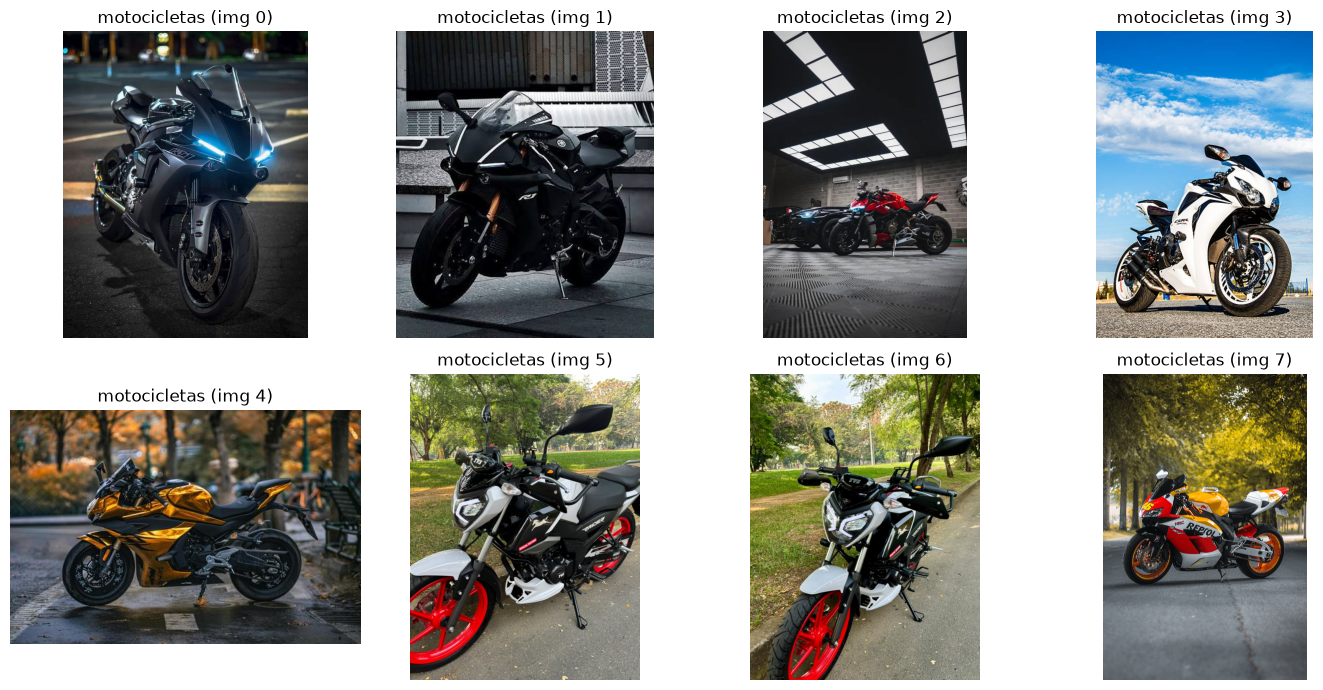

In [3]:
# Mostramos 8 imágenes de motocicletas del dataset
idx_motos = [i for i, lab in enumerate(labels) if lab == "motocicletas"]
n = min(8, len(idx_motos))

plt.figure(figsize=(14, 7))

for k, i in enumerate(idx_motos[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_rgb[i])
    plt.title(f"{labels[i]} (img {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()

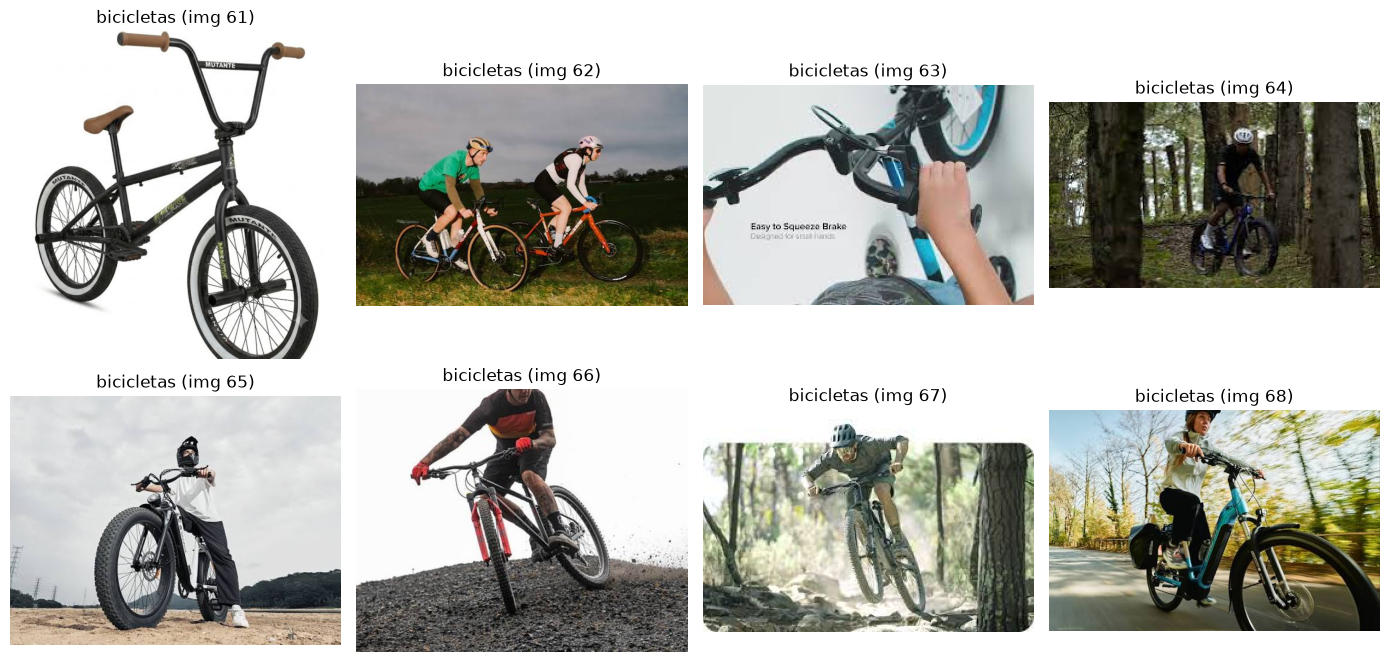

In [4]:
# Mostramos8 imágenes de bicicletas
idx_bicis = [i for i, lab in enumerate(labels) if lab == "bicicletas"]
n = min(8, len(idx_bicis))

plt.figure(figsize=(14, 7))

for k, i in enumerate(idx_bicis[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_rgb[i])
    plt.title(f"{labels[i]} (img {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()

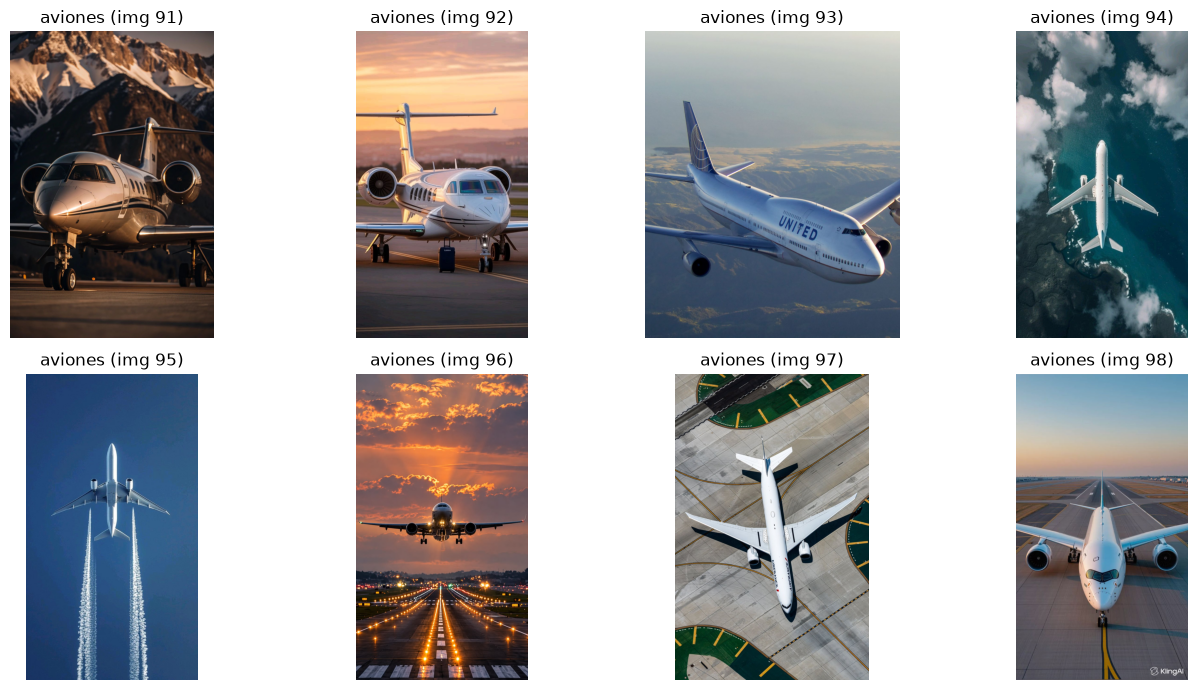

In [5]:
# Mostramos8 imágenes de aviones
idx_bicis = [i for i, lab in enumerate(labels) if lab == "aviones"]
n = min(8, len(idx_bicis))

plt.figure(figsize=(14, 7))

for k, i in enumerate(idx_bicis[:n]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(images_rgb[i])
    plt.title(f"{labels[i]} (img {i})")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Extracción de características

## Algoritmos SIFT

In [ ]:
sift = cv2.SIFT_create()

images_gray = []
all_desc_list = []   # Descriptores
n_keypoints = []

for img_rgb in images_rgb:
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    images_gray.append(gray)
    keypoints, descriptors = sift.detectAndCompute(gray, None) # Detecta puntos y calcula descriptores (SIFT = 128D por keypoint)

    if descriptors is None:
        descriptors = np.zeros((0, 128), dtype=np.float32)

    all_desc_list.append(descriptors)
    n_keypoints.append(len(keypoints))

print("Keypoints por imagen:", n_keypoints)


plt.figure(figsize=(10,5)) # Dónde aparece SIFT

for i, idx in enumerate([0, len(images_rgb)//2]):

    img_kp = cv2.drawKeypoints(images_rgb[idx], sift.detect(images_gray[idx], None), None,
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.subplot(1,2,i+1); plt.imshow(img_kp); plt.title(f"KP image {idx} (n={n_keypoints[idx]})"); plt.axis('off')

plt.tight_layout(); plt.show()


## Algoritmo ORB

Keypoints ORB por imagen: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 968, 973, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 806, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 604, 679, 1000, 1000, 757, 1000, 1000, 815, 1000, 1000, 790, 1000, 1000, 1000, 728, 1000, 1000, 1000, 798, 1000, 686, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


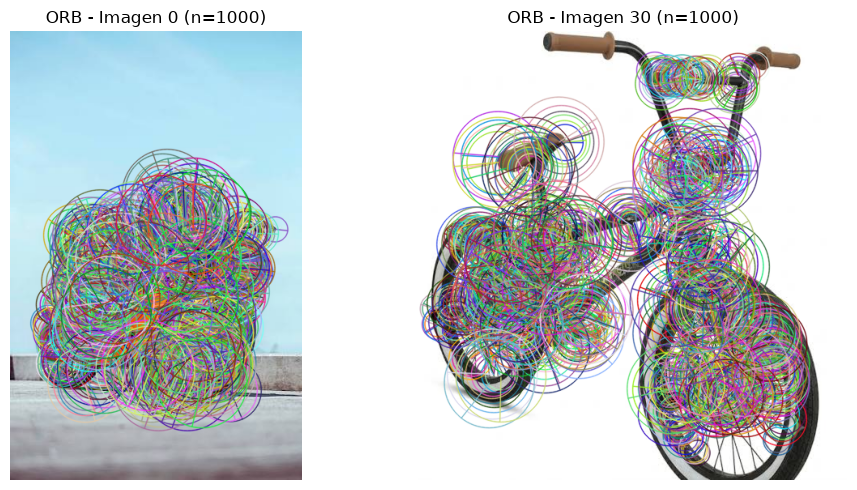

In [6]:

# Crear el detector ORB
orb = cv2.ORB_create(nfeatures=1000)

images_gray_orb = []
all_desc_list_orb = []   # Descriptores ORB
n_keypoints_orb = []

for img_rgb in images_rgb:

    # Convertir la imagen a escala de grises
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    images_gray_orb.append(gray)

    # Detectar puntos clave y calcular descriptores ORB
    keypoints, descriptors = orb.detectAndCompute(gray, None)

    # Si no se detectan descriptores, crear un arreglo vacío
    if descriptors is None:
        descriptors = np.zeros((0, 32), dtype=np.uint8)

    # Guardar los descriptores y la cantidad de puntos clave
    all_desc_list_orb.append(descriptors)
    n_keypoints_orb.append(len(keypoints))

print("Keypoints ORB por imagen:", n_keypoints_orb)


# Visualizar los puntos clave detectados por ORB
plt.figure(figsize=(10, 5))

for i, idx in enumerate([0, len(images_rgb)//2]):

    img_kp = cv2.drawKeypoints(
        images_rgb[idx],
        orb.detect(images_gray_orb[idx], None),
        None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    plt.subplot(1, 2, i + 1)
    plt.imshow(img_kp)
    plt.title(f"ORB - Imagen {idx} (n={n_keypoints_orb[idx]})")
    plt.axis("off")

plt.tight_layout()
plt.show()


# Construcción de diccionario/vocabulario

In [13]:
# Separar las imágenes en entrenamiento y prueba

indices = np.arange(len(images_rgb))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.40,
    random_state=42,
    stratify=labels
)

print("Imágenes de entrenamiento:", len(train_idx))
print("Imágenes de prueba:", len(test_idx))

Imágenes de entrenamiento: 36
Imágenes de prueba: 24


In [14]:
# Reunir descriptores SIFT únicamente de las imágenes de entrenamiento

desc_stack = []

for i in train_idx:

    desc = all_desc_list[i]

    # Muestreo de máximo 400 descriptores por imagen
    if len(desc) > 400:
        idx = np.random.choice(
            len(desc),
            400,
            replace=False
        )
        desc = desc[idx]

    if len(desc) > 0:
        desc_stack.append(desc)

if len(desc_stack) == 0:
    raise RuntimeError(
        "No hay descriptores SIFT en las imágenes de entrenamiento."
    )

# Unir los descriptores en una sola matriz
desc_stack = np.vstack(desc_stack).astype(np.float32)

print("Descriptores de entrenamiento:", desc_stack.shape)

# Construir el diccionario visual
K = 120

kmeans = MiniBatchKMeans(
    n_clusters=K,
    random_state=42,
    batch_size=2048,
    n_init="auto"
)

kmeans.fit(desc_stack)

centers = kmeans.cluster_centers_

print("Diccionario visual entrenado.")
print("Forma de los centros:", centers.shape)

Descriptores de entrenamiento: (14103, 128)
Diccionario visual entrenado.
Forma de los centros: (120, 128)


In [47]:
comparacion = pd.DataFrame({
    "Imagen": range(len(images_rgb)),
    "Keypoints SIFT": n_keypoints,
    "Keypoints ORB": n_keypoints_orb
})

comparacion.head(11)

,Imagen,Keypoints SIFT,Keypoints ORB
0,0,734,1000
1,1,6029,1000
2,2,1208,1000
3,3,1815,1000
4,4,336,1000
5,5,811,1000
6,6,1676,1000
7,7,1516,1000
8,8,735,1000
9,9,840,1000


# Cuantificación vectorial

X (BoVW): (60, 120)  y: (60,)   (K = 120 )


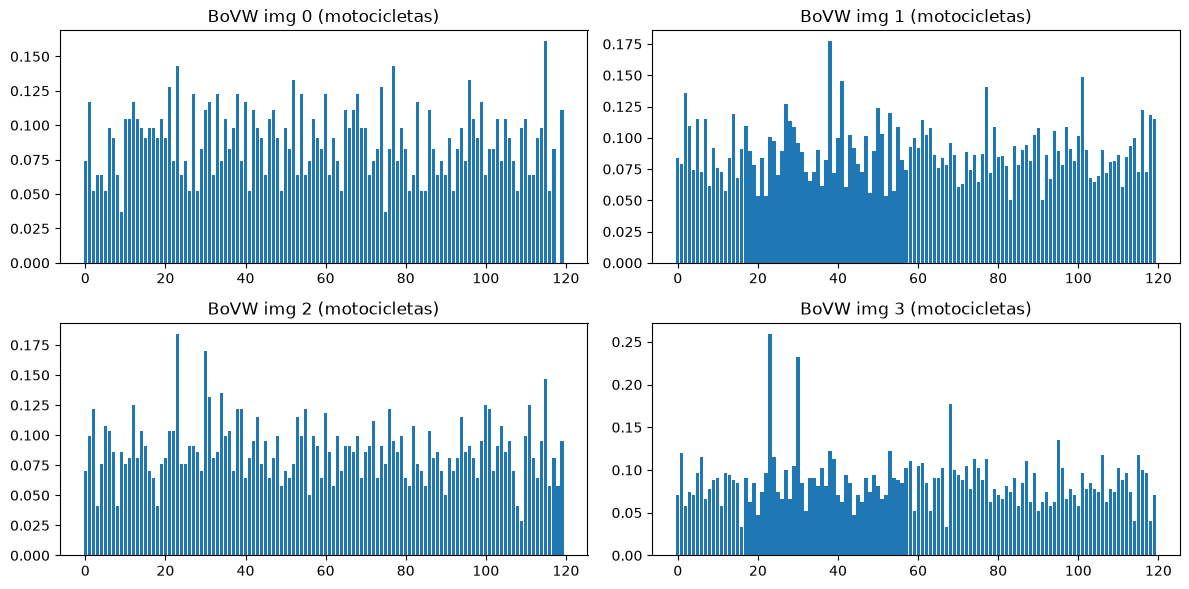

In [11]:
bovw_list = [] # # Codifica cada imagen como histograma BoVW

for i, desc in enumerate(all_desc_list):
    if len(desc) == 0:

        hist = np.zeros(K, dtype=np.float32)
    else:
        # Asignación dura (hard assignment): cada descriptor -> centro más cercano
        # predict() devuelve el índice del cluster para cada descriptor
        word_ids = kmeans.predict(desc)               # shape: (num_desc,)
        hist = np.bincount(word_ids, minlength=K)     # cuentas por palabra visual (0..K-1)
        hist = hist.astype(np.float32)

    # Normalización recomendada (power-law + L2)
    hist = np.sqrt(hist)
    norm = np.linalg.norm(hist) + 1e-8
    hist = hist / norm

    bovw_list.append(hist)

X = np.vstack(bovw_list)             # shape: (num_imagenes, K)
y = np.array(labels)                 # etiquetas: "cat"/"dog"

print("X (BoVW):", X.shape, " y:", y.shape, "  (K =", K, ")")


plt.figure(figsize=(12,6))

for i in range(4): # Visualización: histogramas BoVW de 4 imágenes
    plt.subplot(2,2,i+1)
    plt.bar(np.arange(K), X[i])
    plt.title(f"BoVW img {i} ({y[i]})")
    plt.tight_layout()
plt.show()

# Clasificación (Laboratorio)

Accuracy (SVM lineal): 70.83%

Reporte de clasificación:
               precision    recall  f1-score   support

  bicicletas       0.73      0.67      0.70        12
motocicletas       0.69      0.75      0.72        12

    accuracy                           0.71        24
   macro avg       0.71      0.71      0.71        24
weighted avg       0.71      0.71      0.71        24



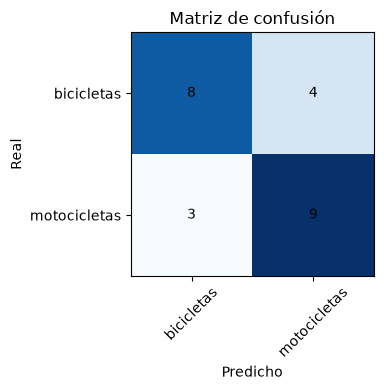

In [15]:
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

clf = LinearSVC(C=1.0, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print("Accuracy (SVM lineal):", f"{acc*100:.2f}%")
print("\nReporte de clasificación:\n", classification_report(y_test, y_pred))

classes = sorted(list(set(y)))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.title("Matriz de confusión")
plt.xticks(range(len(classes)), classes, rotation=45)
plt.yticks(range(len(classes)), classes)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha='center', va='center')

plt.xlabel("Predicho"); plt.ylabel("Real")
plt.tight_layout(); plt.show()
